In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/sram_fault_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (450, 33)


,sample_id,corner_id,pvt_type,vdd_v,temperature_c,fault_class,fault_name,fault_target,severity_value,i_ddq_uA,...,is_bistable,iddq_norm,t_write_norm,dv_bl_norm,snm_hold_norm,snm_read_norm,read_write_delay_ratio,snm_ratio,dv_bl_vdd_ratio,converged
0,SRAM_F0_S0_M40C_0P9V_0001,C_M40C_0P9V,ood,0.9,-40.0,0,healthy,none,0.0,0.0418,...,1,1.0,1.0000,1.0000,1.0,1.0,1.1441,0.5738,0.1513,1
1,SRAM_F1_M5_S1_M40C_0P9V_0002,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,200.0,0.0418,...,1,1.0,1.0111,1.0000,1.0,1.0,1.1315,0.5738,0.1513,1
2,SRAM_F1_M5_S2_M40C_0P9V_0003,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,500.0,0.0418,...,1,1.0,1.0285,0.9996,1.0,1.0,1.1130,0.5738,0.1513,1
3,SRAM_F1_M5_S3_M40C_0P9V_0004,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,1000.0,0.0418,...,1,1.0,1.0592,0.9993,1.0,1.0,1.0808,0.5738,0.1512,1
4,SRAM_F1_M5_S4_M40C_0P9V_0005,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,2000.0,0.0418,...,1,1.0,1.1141,0.9985,1.0,1.0,1.0281,0.5738,0.1511,1


In [3]:
print("Duplicate rows:", df.duplicated().sum())

print("\nConstant columns:")
for col in df.columns:
    if df[col].nunique(dropna=False) <= 1:
        print(col)

print("\nMissing values:")
display(df.isnull().sum())

Duplicate rows: 0

Constant columns:
snm_asym_hold_v

Missing values:


sample_id                 0
corner_id                 0
pvt_type                  0
vdd_v                     0
temperature_c             0
fault_class               0
fault_name                0
fault_target              0
severity_value            0
i_ddq_uA                  0
t_write_ps                0
i_write_peak_mA           0
dv_bl_strobe_mV           0
t_sense_ps                0
v_bump_mV                 0
hold_pass                 0
write_pass                0
read_stable_pass          0
snm_hold_v                0
snm_read_v                0
snm_asym_hold_v           0
snm_asym_read_v           0
snm_drop_v                0
is_bistable               0
iddq_norm                 0
t_write_norm              0
dv_bl_norm                0
snm_hold_norm             0
snm_read_norm             0
read_write_delay_ratio    0
snm_ratio                 0
dv_bl_vdd_ratio           0
converged                 0
dtype: int64

In [4]:
print("Duplicate rows:", df.duplicated().sum())

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("\nConstant columns:", constant_columns)

Duplicate rows: 0

Constant columns: ['snm_asym_hold_v']


In [5]:
numerical_df = df.select_dtypes(include=np.number)

corr_matrix = numerical_df.corr(method="spearman").abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"] >= 0.90
].sort_values("Correlation", ascending=False)

display(high_corr_pairs.round(4))

,Feature 1,Feature 2,Correlation
178,dv_bl_strobe_mV,dv_bl_vdd_ratio,0.9957
161,dv_bl_strobe_mV,t_sense_ps,0.9790
196,t_sense_ps,dv_bl_vdd_ratio,0.9755
216,hold_pass,read_stable_pass,0.9240
314,is_bistable,converged,0.9203
215,hold_pass,write_pass,0.9109


In [6]:
print("Duplicate rows:", df.duplicated().sum())

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_columns)

Duplicate rows: 0
Constant columns: ['snm_asym_hold_v']


In [7]:
initial_excluded = [
    "sample_id",
    "corner_id",
    "fault_name",
    "fault_target",
    "fault_class",
    "severity_value",
    "converged",
    "hold_pass",
    "write_pass",
    "read_stable_pass",
    "is_bistable",
    "snm_asym_hold_v",
    "snm_drop_v",
    "iddq_norm",
    "t_write_norm",
    "dv_bl_norm",
    "snm_hold_norm",
    "snm_read_norm",
    "read_write_delay_ratio",
    "snm_ratio",
    "dv_bl_vdd_ratio"
]

X_initial = df.drop(
    columns=initial_excluded,
    errors="ignore"
).copy()

print("Initial feature count:", X_initial.shape[1])
print("\nInitial features:")
print(X_initial.columns.tolist())

Initial feature count: 12

Initial features:
['pvt_type', 'vdd_v', 'temperature_c', 'i_ddq_uA', 't_write_ps', 'i_write_peak_mA', 'dv_bl_strobe_mV', 't_sense_ps', 'v_bump_mV', 'snm_hold_v', 'snm_read_v', 'snm_asym_read_v']


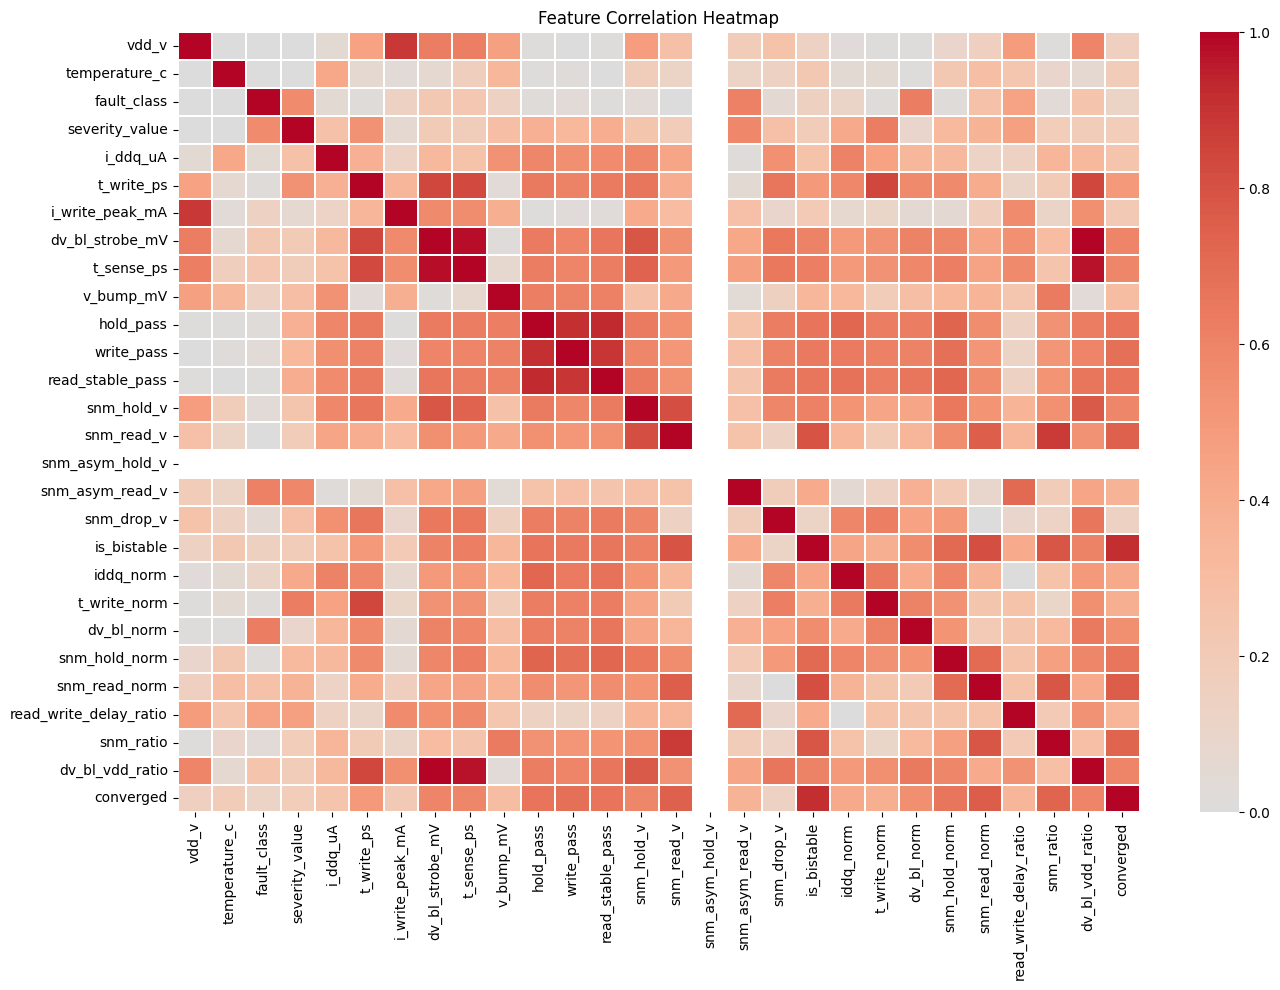

In [8]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [9]:
target = "fault_class"

exclude_columns = [
    # Identifiers
    "sample_id",
    "corner_id",

    # Target descriptions and potential leakage
    "fault_name",
    "fault_target",
    "severity_value",

    # Simulation outcomes
    "hold_pass",
    "write_pass",
    "read_stable_pass",
    "is_bistable",
    "converged",

    # Constant or redundant features
    "snm_asym_hold_v",
    "snm_drop_v",
    "iddq_norm",
    "t_write_norm",
    "dv_bl_norm",
    "snm_hold_norm",
    "snm_read_norm",
    "read_write_delay_ratio",
    "snm_ratio",
    "dv_bl_vdd_ratio"
]

print("Columns to exclude:", len(exclude_columns))

Columns to exclude: 20


In [10]:
X = df.drop(columns=exclude_columns + [target], errors="ignore").copy()

y = df[target].copy()

# Remove any constant columns automatically
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X.drop(columns=constant_columns, inplace=True)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nRemaining features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature matrix shape: (450, 12)
Target shape: (450,)

Remaining features:
['pvt_type', 'vdd_v', 'temperature_c', 'i_ddq_uA', 't_write_ps', 'i_write_peak_mA', 'dv_bl_strobe_mV', 't_sense_ps', 'v_bump_mV', 'snm_hold_v', 'snm_read_v', 'snm_asym_read_v']

Target distribution:
fault_class
0     15
1    180
2     75
3     90
4     90
Name: count, dtype: int64


In [11]:
feature_df = X.copy()
feature_df[target] = y

feature_df.to_csv(
    "../data/sram_cleaned_features.csv",
    index=False
)

print("Cleaned feature dataset saved successfully!")

Cleaned feature dataset saved successfully!


In [12]:
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", feature_df.duplicated().sum())

display(feature_df.head())

Missing values: 0
Duplicate rows: 7


,pvt_type,vdd_v,temperature_c,i_ddq_uA,t_write_ps,i_write_peak_mA,dv_bl_strobe_mV,t_sense_ps,v_bump_mV,snm_hold_v,snm_read_v,snm_asym_read_v,fault_class
0,ood,0.9,-40.0,0.0418,71.8,0.028,136.2,82.2,84.2,0.3501,0.2009,0.0,0
1,ood,0.9,-40.0,0.0418,72.7,0.028,136.2,82.2,84.2,0.3501,0.2009,0.0,1
2,ood,0.9,-40.0,0.0418,73.9,0.028,136.1,82.2,84.2,0.3501,0.2009,0.0,1
3,ood,0.9,-40.0,0.0418,76.1,0.028,136.1,82.2,84.2,0.3501,0.2009,0.0,1
4,ood,0.9,-40.0,0.0418,80.0,0.028,136.0,82.3,84.2,0.3501,0.2009,0.0,1


In [13]:
duplicates = feature_df[
    feature_df.duplicated(keep=False)
].sort_values(by=list(feature_df.columns))

print("Rows involved in duplicates:", len(duplicates))

display(duplicates)

Rows involved in duplicates: 14


,pvt_type,vdd_v,temperature_c,i_ddq_uA,t_write_ps,i_write_peak_mA,dv_bl_strobe_mV,t_sense_ps,v_bump_mV,snm_hold_v,snm_read_v,snm_asym_read_v,fault_class
152,ood,1.0,-40.0,0.0062,61.2,0.039,227.6,61.4,107.2,0.4501,0.2580,0.0000,1
158,ood,1.0,-40.0,0.0062,61.2,0.039,227.6,61.4,107.2,0.4501,0.2580,0.0000,1
181,ood,1.0,0.0,0.0048,60.8,0.037,224.1,60.8,117.7,0.4903,0.2798,0.0000,1
187,ood,1.0,0.0,0.0048,60.8,0.037,224.1,60.8,117.7,0.4903,0.2798,0.0000,1
241,ood,1.0,75.0,0.8553,60.5,0.033,229.9,57.8,138.3,0.4319,0.2298,0.0000,1
247,ood,1.0,75.0,0.8553,60.5,0.033,229.9,57.8,138.3,0.4319,0.2298,0.0000,1
331,ood,1.1,0.0,0.0028,53.4,0.043,327.1,49.4,140.7,0.5105,0.2824,0.0001,1
337,ood,1.1,0.0,0.0028,53.4,0.043,327.1,49.4,140.7,0.5105,0.2824,0.0001,1
332,ood,1.1,0.0,0.0028,54.5,0.043,326.9,49.5,140.7,0.5105,0.2824,0.0001,1
338,ood,1.1,0.0,0.0028,54.5,0.043,326.9,49.5,140.7,0.5105,0.2824,0.0001,1


In [14]:
print("Original duplicate rows:", df.duplicated().sum())

print(
    "Duplicates based on electrical features:",
    X.duplicated().sum()
)

Original duplicate rows: 0
Duplicates based on electrical features: 7


In [15]:
duplicate_check = (
    feature_df.groupby(list(X.columns))["fault_class"]
    .nunique()
)

print(
    "Identical feature combinations with different fault classes:",
    (duplicate_check > 1).sum()
)

Identical feature combinations with different fault classes: 0


In [16]:
duplicate_check = (
    feature_df.groupby(list(X.columns))["fault_class"]
    .nunique()
)

print(
    "Identical feature combinations with different fault classes:",
    (duplicate_check > 1).sum()
)

Identical feature combinations with different fault classes: 0


In [17]:
duplicate_rows = feature_df[
    feature_df.duplicated(subset=X.columns, keep=False)
]

display(
    duplicate_rows.sort_values(
        by=list(X.columns) + ["fault_class"]
    )
)

,pvt_type,vdd_v,temperature_c,i_ddq_uA,t_write_ps,i_write_peak_mA,dv_bl_strobe_mV,t_sense_ps,v_bump_mV,snm_hold_v,snm_read_v,snm_asym_read_v,fault_class
152,ood,1.0,-40.0,0.0062,61.2,0.039,227.6,61.4,107.2,0.4501,0.2580,0.0000,1
158,ood,1.0,-40.0,0.0062,61.2,0.039,227.6,61.4,107.2,0.4501,0.2580,0.0000,1
181,ood,1.0,0.0,0.0048,60.8,0.037,224.1,60.8,117.7,0.4903,0.2798,0.0000,1
187,ood,1.0,0.0,0.0048,60.8,0.037,224.1,60.8,117.7,0.4903,0.2798,0.0000,1
241,ood,1.0,75.0,0.8553,60.5,0.033,229.9,57.8,138.3,0.4319,0.2298,0.0000,1
247,ood,1.0,75.0,0.8553,60.5,0.033,229.9,57.8,138.3,0.4319,0.2298,0.0000,1
331,ood,1.1,0.0,0.0028,53.4,0.043,327.1,49.4,140.7,0.5105,0.2824,0.0001,1
337,ood,1.1,0.0,0.0028,53.4,0.043,327.1,49.4,140.7,0.5105,0.2824,0.0001,1
332,ood,1.1,0.0,0.0028,54.5,0.043,326.9,49.5,140.7,0.5105,0.2824,0.0001,1
338,ood,1.1,0.0,0.0028,54.5,0.043,326.9,49.5,140.7,0.5105,0.2824,0.0001,1


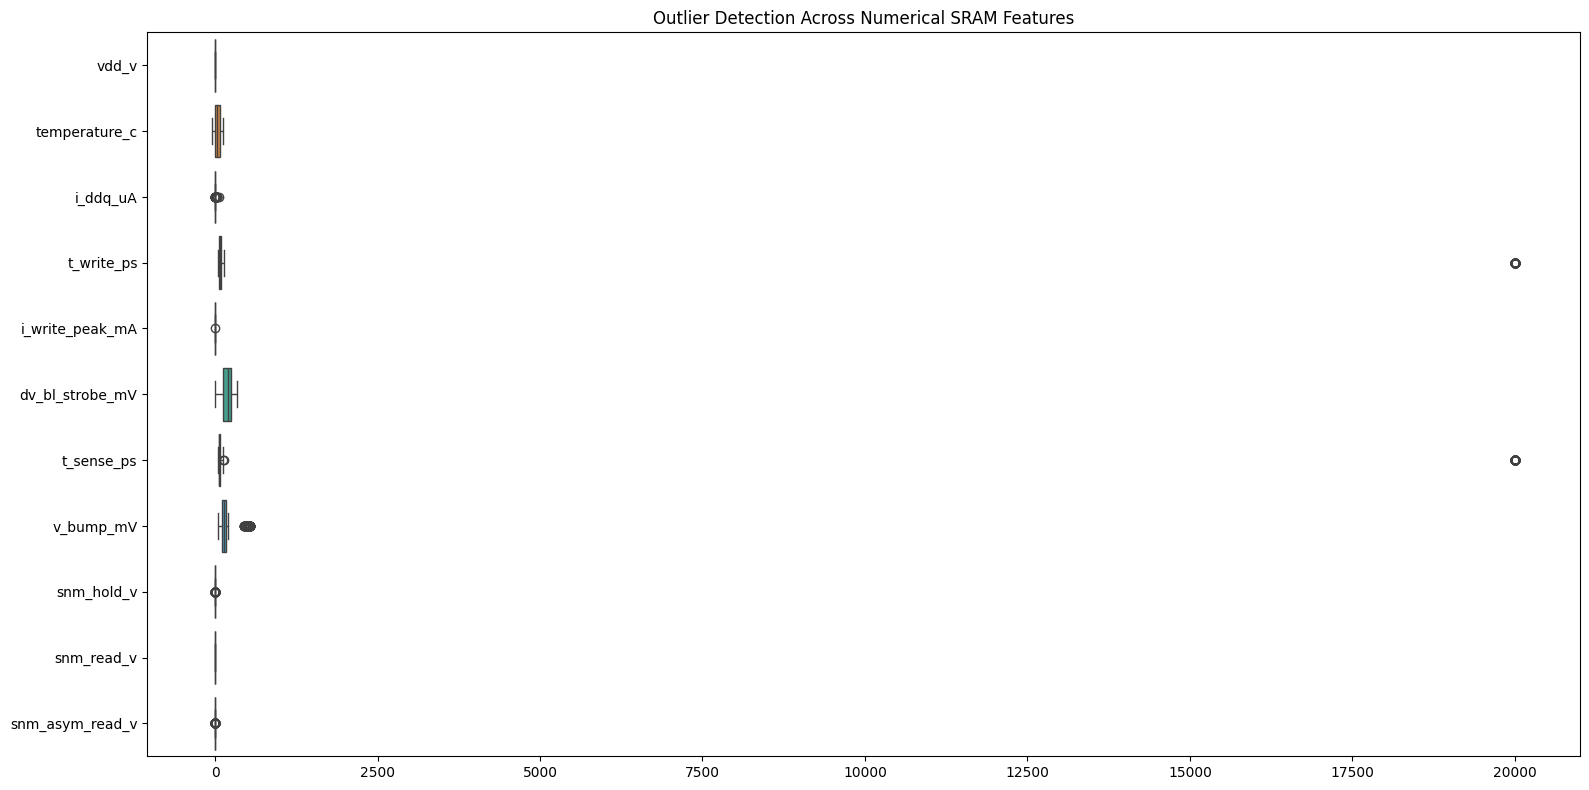

In [18]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=X[numerical_features],
    orient="h"
)

plt.title("Outlier Detection Across Numerical SRAM Features")
plt.tight_layout()
plt.show()

In [19]:
outlier_results = []

for feature in numerical_features:

    Q1 = X[feature].quantile(0.25)
    Q3 = X[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X[
        (X[feature] < lower) |
        (X[feature] > upper)
    ][feature]

    outlier_results.append({
        "Feature": feature,
        "Outlier Count": len(outliers),
        "Lower Bound": lower,
        "Upper Bound": upper
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(4))

,Feature,Outlier Count,Lower Bound,Upper Bound
0,vdd_v,0,0.6000,1.4000
1,temperature_c,0,-112.5000,187.5000
2,i_ddq_uA,58,-1.0833,1.8183
3,t_write_ps,75,5.1250,150.9250
4,i_write_peak_mA,1,-0.0045,0.0715
5,dv_bl_strobe_mV,0,-47.5875,420.7125
6,t_sense_ps,77,11.7875,126.4875
7,v_bump_mV,75,26.4125,241.9125
8,snm_hold_v,77,0.2191,0.6207
9,snm_read_v,0,-0.3955,0.6592


In [20]:
features_to_check = [
    "i_ddq_uA",
    "t_write_ps",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_asym_read_v"
]

for feature in features_to_check:

    Q1 = X[feature].quantile(0.25)
    Q3 = X[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask = (
        (X[feature] < lower) |
        (X[feature] > upper)
    )

    result = df.loc[outlier_mask, "fault_class"].value_counts()

    print(f"\nOutliers in {feature}")
    print(result.sort_index())


Outliers in i_ddq_uA
fault_class
0     1
1     1
2    55
4     1
Name: count, dtype: int64

Outliers in t_write_ps
fault_class
2    75
Name: count, dtype: int64

Outliers in t_sense_ps
fault_class
2    75
4     2
Name: count, dtype: int64

Outliers in v_bump_mV
fault_class
2    75
Name: count, dtype: int64

Outliers in snm_hold_v
fault_class
2    75
3     1
4     1
Name: count, dtype: int64

Outliers in snm_asym_read_v
fault_class
1    83
Name: count, dtype: int64


In [21]:
skewness = X.select_dtypes(include=np.number).skew()

skewness_df = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})

skewness_df["Distribution"] = np.where(
    skewness_df["Skewness"].abs() < 0.5,
    "Approximately symmetric",
    np.where(
        skewness_df["Skewness"].abs() < 1,
        "Moderately skewed",
        "Highly skewed"
    )
)

display(
    skewness_df.sort_values(
        "Skewness", key=abs, ascending=False
    ).round(4)
)

,Feature,Skewness,Distribution
10,snm_asym_read_v,8.7138,Highly skewed
2,i_ddq_uA,6.7729,Highly skewed
6,t_sense_ps,1.7948,Highly skewed
3,t_write_ps,1.7948,Highly skewed
7,v_bump_mV,1.6848,Highly skewed
8,snm_hold_v,-1.4255,Highly skewed
9,snm_read_v,-0.6486,Moderately skewed
4,i_write_peak_mA,0.4613,Approximately symmetric
5,dv_bl_strobe_mV,-0.3525,Approximately symmetric
1,temperature_c,0.2188,Approximately symmetric


In [22]:
# Create experimental transformed features
X_transformed = X.copy()

X_transformed["log_i_ddq"] = np.log1p(X["i_ddq_uA"])

X_transformed["log_v_bump"] = np.log1p(X["v_bump_mV"])

print("Transformed features created.")

display(
    X_transformed[
        ["i_ddq_uA", "log_i_ddq", "v_bump_mV", "log_v_bump"]
    ].head()
)

Transformed features created.


,i_ddq_uA,log_i_ddq,v_bump_mV,log_v_bump
0,0.0418,0.04095,84.2,4.445001
1,0.0418,0.04095,84.2,4.445001
2,0.0418,0.04095,84.2,4.445001
3,0.0418,0.04095,84.2,4.445001
4,0.0418,0.04095,84.2,4.445001


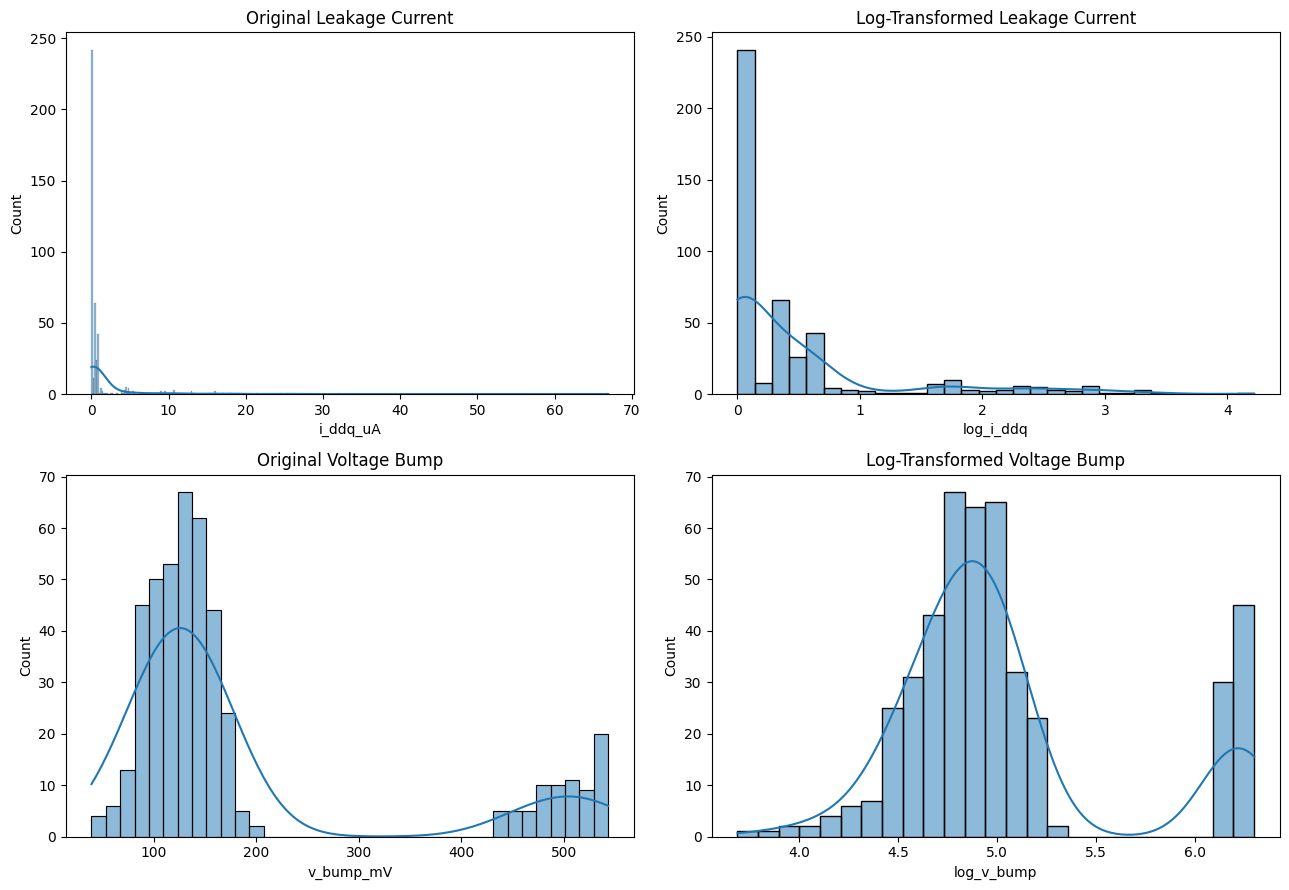

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(X["i_ddq_uA"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Original Leakage Current")

sns.histplot(X_transformed["log_i_ddq"], kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Log-Transformed Leakage Current")

sns.histplot(X["v_bump_mV"], kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Original Voltage Bump")

sns.histplot(X_transformed["log_v_bump"], kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Log-Transformed Voltage Bump")

plt.tight_layout()
plt.show()

In [24]:
print("Original i_ddq skewness:", X["i_ddq_uA"].skew())
print("Transformed i_ddq skewness:", X_transformed["log_i_ddq"].skew())

print("\nOriginal v_bump skewness:", X["v_bump_mV"].skew())
print("Transformed v_bump skewness:", X_transformed["log_v_bump"].skew())

Original i_ddq skewness: 6.772916308841848
Transformed i_ddq skewness: 2.2383264600634125

Original v_bump skewness: 1.6847972445817454
Transformed v_bump skewness: 1.1028685995472167


In [25]:
print("LEAKAGE CURRENT")
print("Original:", X["i_ddq_uA"].skew())
print("Log:", X_transformed["log_i_ddq"].skew())

print("\nVOLTAGE BUMP")
print("Original:", X["v_bump_mV"].skew())
print("Log:", X_transformed["log_v_bump"].skew())

LEAKAGE CURRENT
Original: 6.772916308841848
Log: 2.2383264600634125

VOLTAGE BUMP
Original: 1.6847972445817454
Log: 1.1028685995472167


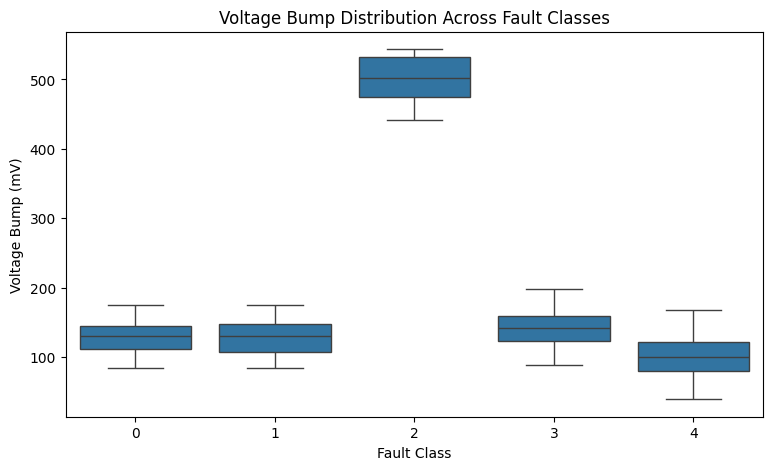

In [26]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="fault_class",
    y="v_bump_mV"
)

plt.title("Voltage Bump Distribution Across Fault Classes")
plt.xlabel("Fault Class")
plt.ylabel("Voltage Bump (mV)")
plt.show()

In [27]:
display(
    df.groupby("fault_class")["v_bump_mV"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(3)
)

,count,min,median,mean,max
fault_class,,,,,
0,15,84.2,129.90,128.160,175.1
1,180,84.2,129.90,128.143,175.1
2,75,441.4,502.60,500.997,543.5
3,90,87.9,141.75,142.061,197.7
4,90,39.0,100.00,100.418,166.9


In [28]:
# Create a separate engineered feature dataset
X_engineered = X.copy()

# Log transformation of leakage current
X_engineered["log_i_ddq"] = np.log1p(
    X_engineered["i_ddq_uA"]
)

print("New feature created: log_i_ddq")

display(
    X_engineered[
        ["i_ddq_uA", "log_i_ddq"]
    ].head(10)
)

New feature created: log_i_ddq


,i_ddq_uA,log_i_ddq
0,0.0418,0.04095
1,0.0418,0.04095
2,0.0418,0.04095
3,0.0418,0.04095
4,0.0418,0.04095
5,0.0418,0.04095
6,0.0418,0.04095
7,0.0418,0.04095
8,0.0418,0.04095
9,0.0418,0.04095


In [29]:
print("Original skewness:",
      X_engineered["i_ddq_uA"].skew())

print("Transformed skewness:",
      X_engineered["log_i_ddq"].skew())

Original skewness: 6.772916308841848
Transformed skewness: 2.2383264600634125


In [30]:
# Difference between hold stability and read stability
X_engineered["snm_margin_gap_v"] = (
    X_engineered["snm_hold_v"] -
    X_engineered["snm_read_v"]
)

print("SNM margin-gap feature created!")

display(
    X_engineered[
        ["snm_hold_v", "snm_read_v", "snm_margin_gap_v"]
    ].head(10)
)

SNM margin-gap feature created!


,snm_hold_v,snm_read_v,snm_margin_gap_v
0,0.3501,0.2009,0.1492
1,0.3501,0.2009,0.1492
2,0.3501,0.2009,0.1492
3,0.3501,0.2009,0.1492
4,0.3501,0.2009,0.1492
5,0.3501,0.2009,0.1492
6,0.3501,0.2009,0.1492
7,0.3501,0.2009,0.1492
8,0.3501,0.2009,0.1492
9,0.3501,0.2009,0.1492


In [31]:
difference = (
    df["snm_drop_v"] -
    X_engineered["snm_margin_gap_v"]
)

print("Maximum absolute difference:",
      difference.abs().max())

print("Are they identical?",
      np.allclose(
          df["snm_drop_v"],
          X_engineered["snm_margin_gap_v"]
      ))

Maximum absolute difference: 5.551115123125783e-17
Are they identical? True


In [32]:
class_labels = {
    0: "Healthy",
    1: "Resistive Open",
    2: "Bridging",
    3: "Storage Vth Drift",
    4: "Access Vth Drift"
}

snm_gap_summary = (
    pd.DataFrame({
        "snm_margin_gap_v": X_engineered["snm_margin_gap_v"],
        "fault_class": y
    })
    .groupby("fault_class")["snm_margin_gap_v"]
    .agg(["count", "median", "mean", "std"])
)

snm_gap_summary.index = snm_gap_summary.index.map(class_labels)

display(snm_gap_summary.round(5))

,count,median,mean,std
fault_class,,,,
Healthy,15,0.20640,0.21664,0.05753
Resistive Open,180,0.20640,0.21770,0.05720
Bridging,75,0.00000,0.00000,0.00000
Storage Vth Drift,90,0.24410,0.27548,0.09126
Access Vth Drift,90,0.18045,0.20259,0.10293


In [33]:
# Identify whether asymmetric read SNM is nonzero
X_engineered["snm_asym_read_present"] = (
    X_engineered["snm_asym_read_v"] > 0
).astype(int)

print("Feature created!")

print(
    X_engineered["snm_asym_read_present"].value_counts()
)

Feature created!
snm_asym_read_present
0    317
1    133
Name: count, dtype: int64


In [34]:
asym_analysis = pd.crosstab(
    y,
    X_engineered["snm_asym_read_present"],
    margins=True
)

asym_analysis.index = [
    class_labels.get(i, i) if i != "All" else "All"
    for i in asym_analysis.index
]

display(asym_analysis)

snm_asym_read_present,0,1,All
Healthy,15,0,15
Resistive Open,47,133,180
Bridging,75,0,75
Storage Vth Drift,90,0,90
Access Vth Drift,90,0,90
All,317,133,450


In [35]:
asym_percentage = pd.crosstab(
    y,
    X_engineered["snm_asym_read_present"],
    normalize="index"
) * 100

asym_percentage.index = asym_percentage.index.map(class_labels)

display(asym_percentage.round(2))

snm_asym_read_present,0,1
fault_class,,
Healthy,100.00,0.00
Resistive Open,26.11,73.89
Bridging,100.00,0.00
Storage Vth Drift,100.00,0.00
Access Vth Drift,100.00,0.00


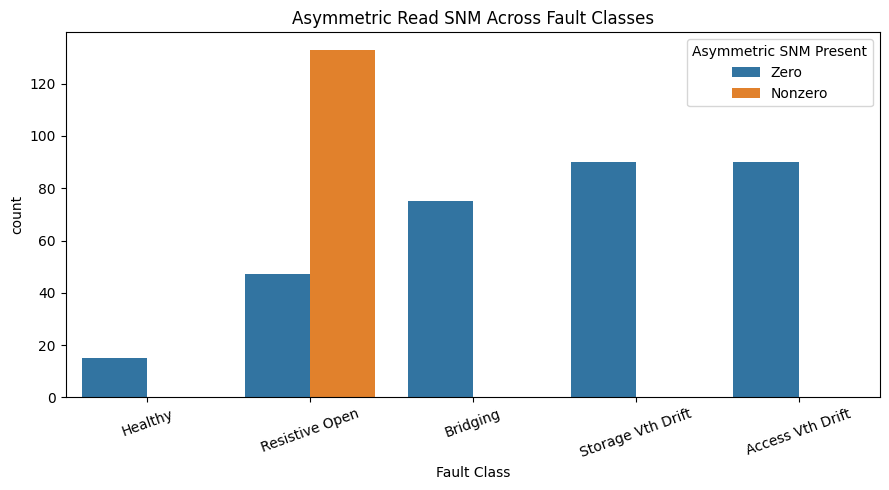

In [36]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=pd.DataFrame({
        "Fault Class": y.map(class_labels),
        "Asymmetric SNM Present":
            X_engineered["snm_asym_read_present"].map({
                0: "Zero",
                1: "Nonzero"
            })
    }),
    x="Fault Class",
    hue="Asymmetric SNM Present"
)

plt.title("Asymmetric Read SNM Across Fault Classes")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [39]:
# Select numerical columns only
X_numeric = X_engineered.select_dtypes(
    include=["int64", "float64"]
)

# Calculate Spearman correlation
correlation_check = X_numeric.corr(
    method="spearman"
)

engineered_features = [
    "log_i_ddq",
    "snm_margin_gap_v",
    "snm_asym_read_present"
]

display(
    correlation_check[engineered_features].round(4)
)

,log_i_ddq,snm_margin_gap_v,snm_asym_read_present
vdd_v,0.0498,0.2640,0.1789
temperature_c,0.4295,-0.1420,0.1240
i_ddq_uA,1.0000,-0.5403,-0.0243
t_write_ps,0.3812,-0.6635,-0.1088
i_write_peak_mA,0.1297,0.0979,0.2715
dv_bl_strobe_mV,-0.3218,0.6493,0.4426
t_sense_ps,0.2652,-0.6530,-0.4681
v_bump_mV,0.5369,-0.1528,0.0318
snm_hold_v,-0.5810,0.5934,0.2802
snm_read_v,-0.4397,0.1373,0.2712


In [40]:
print(
    "SNM gap equals existing SNM drop:",
    np.allclose(
        X_engineered["snm_margin_gap_v"],
        df["snm_drop_v"]
    )
)

print(
    "Log leakage skewness:",
    X_engineered["log_i_ddq"].skew()
)

print(
    "Asymmetric SNM indicator counts:"
)

print(
    X_engineered["snm_asym_read_present"].value_counts()
)

SNM gap equals existing SNM drop: True
Log leakage skewness: 2.2383264600634125
Asymmetric SNM indicator counts:
snm_asym_read_present
0    317
1    133
Name: count, dtype: int64


In [41]:
X_engineered["fault_class"] = y

X_engineered.to_csv(
    "../data/sram_engineered_features.csv",
    index=False
)

print("Engineered dataset saved!")
print("Dataset shape:", X_engineered.shape)

Engineered dataset saved!
Dataset shape: (450, 16)


In [42]:
# Keep the engineered features
# Remove log_v_bump because it did not provide enough benefit

if "log_v_bump" in X_engineered.columns:
    X_engineered.drop(columns=["log_v_bump"], inplace=True)

print("Current features:")
print(X_engineered.columns.tolist())

Current features:
['pvt_type', 'vdd_v', 'temperature_c', 'i_ddq_uA', 't_write_ps', 'i_write_peak_mA', 'dv_bl_strobe_mV', 't_sense_ps', 'v_bump_mV', 'snm_hold_v', 'snm_read_v', 'snm_asym_read_v', 'log_i_ddq', 'snm_margin_gap_v', 'snm_asym_read_present', 'fault_class']


In [43]:
# Add target separately
final_feature_df = X_engineered.copy()
final_feature_df["fault_class"] = y

print("Dataset shape:", final_feature_df.shape)

display(final_feature_df.head())

Dataset shape: (450, 16)


,pvt_type,vdd_v,temperature_c,i_ddq_uA,t_write_ps,i_write_peak_mA,dv_bl_strobe_mV,t_sense_ps,v_bump_mV,snm_hold_v,snm_read_v,snm_asym_read_v,log_i_ddq,snm_margin_gap_v,snm_asym_read_present,fault_class
0,ood,0.9,-40.0,0.0418,71.8,0.028,136.2,82.2,84.2,0.3501,0.2009,0.0,0.04095,0.1492,0,0
1,ood,0.9,-40.0,0.0418,72.7,0.028,136.2,82.2,84.2,0.3501,0.2009,0.0,0.04095,0.1492,0,1
2,ood,0.9,-40.0,0.0418,73.9,0.028,136.1,82.2,84.2,0.3501,0.2009,0.0,0.04095,0.1492,0,1
3,ood,0.9,-40.0,0.0418,76.1,0.028,136.1,82.2,84.2,0.3501,0.2009,0.0,0.04095,0.1492,0,1
4,ood,0.9,-40.0,0.0418,80.0,0.028,136.0,82.3,84.2,0.3501,0.2009,0.0,0.04095,0.1492,0,1


In [44]:
final_feature_df.to_csv(
    "../data/sram_engineered_features.csv",
    index=False
)

print("SRAM engineered dataset saved successfully!")

SRAM engineered dataset saved successfully!


In [45]:
print("Missing values:", final_feature_df.isnull().sum().sum())

print("\nTarget distribution:")
print(final_feature_df["fault_class"].value_counts().sort_index())

print("\nFeature count:",
      final_feature_df.drop(columns=["fault_class"]).shape[1])

Missing values: 0

Target distribution:
fault_class
0     15
1    180
2     75
3     90
4     90
Name: count, dtype: int64

Feature count: 15
